In [1]:
import torch
torch.cuda.is_available()

True

In [2]:
torch.cuda.get_device_name(0)

'NVIDIA GeForce RTX 4050 Laptop GPU'

In [1]:
import torchvision

dataset = torchvision.datasets.OxfordIIITPet(
    root="../data/raw",
    target_types="segmentation",
    split="trainval",
    download=True
)

100%|██████████| 792M/792M [11:51<00:00, 1.11MB/s]    
100%|██████████| 19.2M/19.2M [00:15<00:00, 1.21MB/s]


In [3]:
from PIL import Image
from pathlib import Path
import numpy as np

count = 0

IMAGES_DIR = Path("../data/raw/oxford-iiit-pet/images")

longest_width = []
longest_height = []
for f in IMAGES_DIR.iterdir():
    if f.suffix.lower() in ".jpg":
        with Image.open(f) as im:
            count += 1
            longest_width.append(im.size[0])
            longest_height.append(im.size[1])

print(f"Total images: {count}")
print(f"Longest width: {max(longest_width)}")
print(f"Smallest width: {min(longest_width)}")
print(f"Median width: {np.median(sorted(longest_width))}")
print(f"Longest height: {max(longest_height)}")
print(f"Smallest height: {min(longest_height)}")
print(f"Median height: {np.median(sorted(longest_height))}")

Total images: 7390
Longest width: 3264
Smallest width: 114
Median width: 500.0
Longest height: 2606
Smallest height: 103
Median height: 375.0


In [4]:
with open("../data/raw/oxford-iiit-pet/annotations/list.txt", "r") as f:
    lines = f.readlines()
    print(len(lines))

7355


In [5]:
from pathlib import Path

IMAGES_DIR = Path("../data/raw/oxford-iiit-pet/images")
ANN_DIR = Path("../data/raw/oxford-iiit-pet/annotations")
MASKS_DIR = ANN_DIR / "trimaps"

annotated_stems = set()
with open(ANN_DIR / "list.txt", "r") as f:
    for line in f:
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        annotated_stems.add(line.split()[0])

image_stems = {
    p.stem for p in IMAGES_DIR.iterdir()
    if p.suffix.lower() == ".jpg" and not p.name.startswith("._")
}

not_annotated = image_stems - annotated_stems
missing_image = annotated_stems - image_stems
not_annotated_with_mask = [s for s in not_annotated if (MASKS_DIR / f"{s}.png").exists()]

print("Annotated stems:", len(annotated_stems))
print("Image files:", len(image_stems))
print("Images not in list.txt:", len(not_annotated), sorted(not_annotated)[:5])
print("In list.txt but no image:", len(missing_image))
print("Unannotated images that have a trimap:", len(not_annotated_with_mask))

Annotated stems: 7349
Image files: 7390
Images not in list.txt: 41 ['Abyssinian_34', 'Abyssinian_82', 'Bombay_11', 'Bombay_189', 'Bombay_190']
In list.txt but no image: 0
Unannotated images that have a trimap: 41


In [6]:
RGB_image = []
Non_rgb_image = []

for f in IMAGES_DIR.iterdir():
    if f.suffix.lower() in ".jpg":
        with Image.open(f) as im:
            if im.mode == "RGB":
                RGB_image.append(im)
            else:
                Non_rgb_image.append(im)


In [7]:
print(f"RGB Image: {len(RGB_image)}")
print(f"Non RGB image: {len(Non_rgb_image)}")

RGB Image: 7378
Non RGB image: 12


In [15]:
Non_rgb_image

[<PIL.GifImagePlugin.GifImageFile image mode=P size=250x202>,
 <PIL.PngImagePlugin.PngImageFile image mode=RGBA size=200x150>,
 <PIL.JpegImagePlugin.JpegImageFile image mode=L size=299x325>,
 <PIL.GifImagePlugin.GifImageFile image mode=P size=350x250>,
 <PIL.PngImagePlugin.PngImageFile image mode=RGBA size=582x800>,
 <PIL.GifImagePlugin.GifImageFile image mode=P size=216x188>,
 <PIL.GifImagePlugin.GifImageFile image mode=P size=183x275>,
 <PIL.GifImagePlugin.GifImageFile image mode=P size=246x175>,
 <PIL.PngImagePlugin.PngImageFile image mode=RGBA size=183x275>,
 <PIL.GifImagePlugin.GifImageFile image mode=P size=300x214>,
 <PIL.JpegImagePlugin.JpegImageFile image mode=L size=500x282>,
 <PIL.JpegImagePlugin.JpegImageFile image mode=L size=364x500>]

In [8]:
import random
import matplotlib.pyplot as plt

MASKS_DIR = Path("../data/raw/oxford-iiit-pet/annotations/trimaps")

random.seed(42)

mask_files = sorted(f for f in MASKS_DIR.glob("*.png") if not f.name.startswith("._"))
print("Total masks:", len(mask_files))

Total masks: 7390


In [9]:
sample = random.sample(mask_files, 200)
unique_values = set()
pixel_counts = {}
size_mismatch = []

for m in sample:
    with Image.open(m) as mask:
        arr = np.array(mask)
        mask_size = mask.size
    unique_values.update(np.unique(arr).tolist())
    for v, c in zip(*np.unique(arr, return_counts=True)):
        pixel_counts[int(v)] = pixel_counts.get(int(v), 0) + int(c)

    with Image.open(IMAGES_DIR / (m.stem + ".jpg")) as im:
        if im.size != mask_size:
            size_mismatch.append(m.stem)

In [10]:
print("Mask dtype/shape example:", arr.dtype, arr.shape)
print("Unique mask values:", sorted(unique_values))
total = sum(pixel_counts.values())
for v in sorted(pixel_counts):
    print(f"Value {v}: {pixel_counts[v] / total:.1%} of pixels")
print("Size mismatches (image vs mask):", len(size_mismatch))

Mask dtype/shape example: uint8 (334, 500)
Unique mask values: [1, 2, 3]
Value 1: 30.2% of pixels
Value 2: 58.0% of pixels
Value 3: 11.9% of pixels
Size mismatches (image vs mask): 0


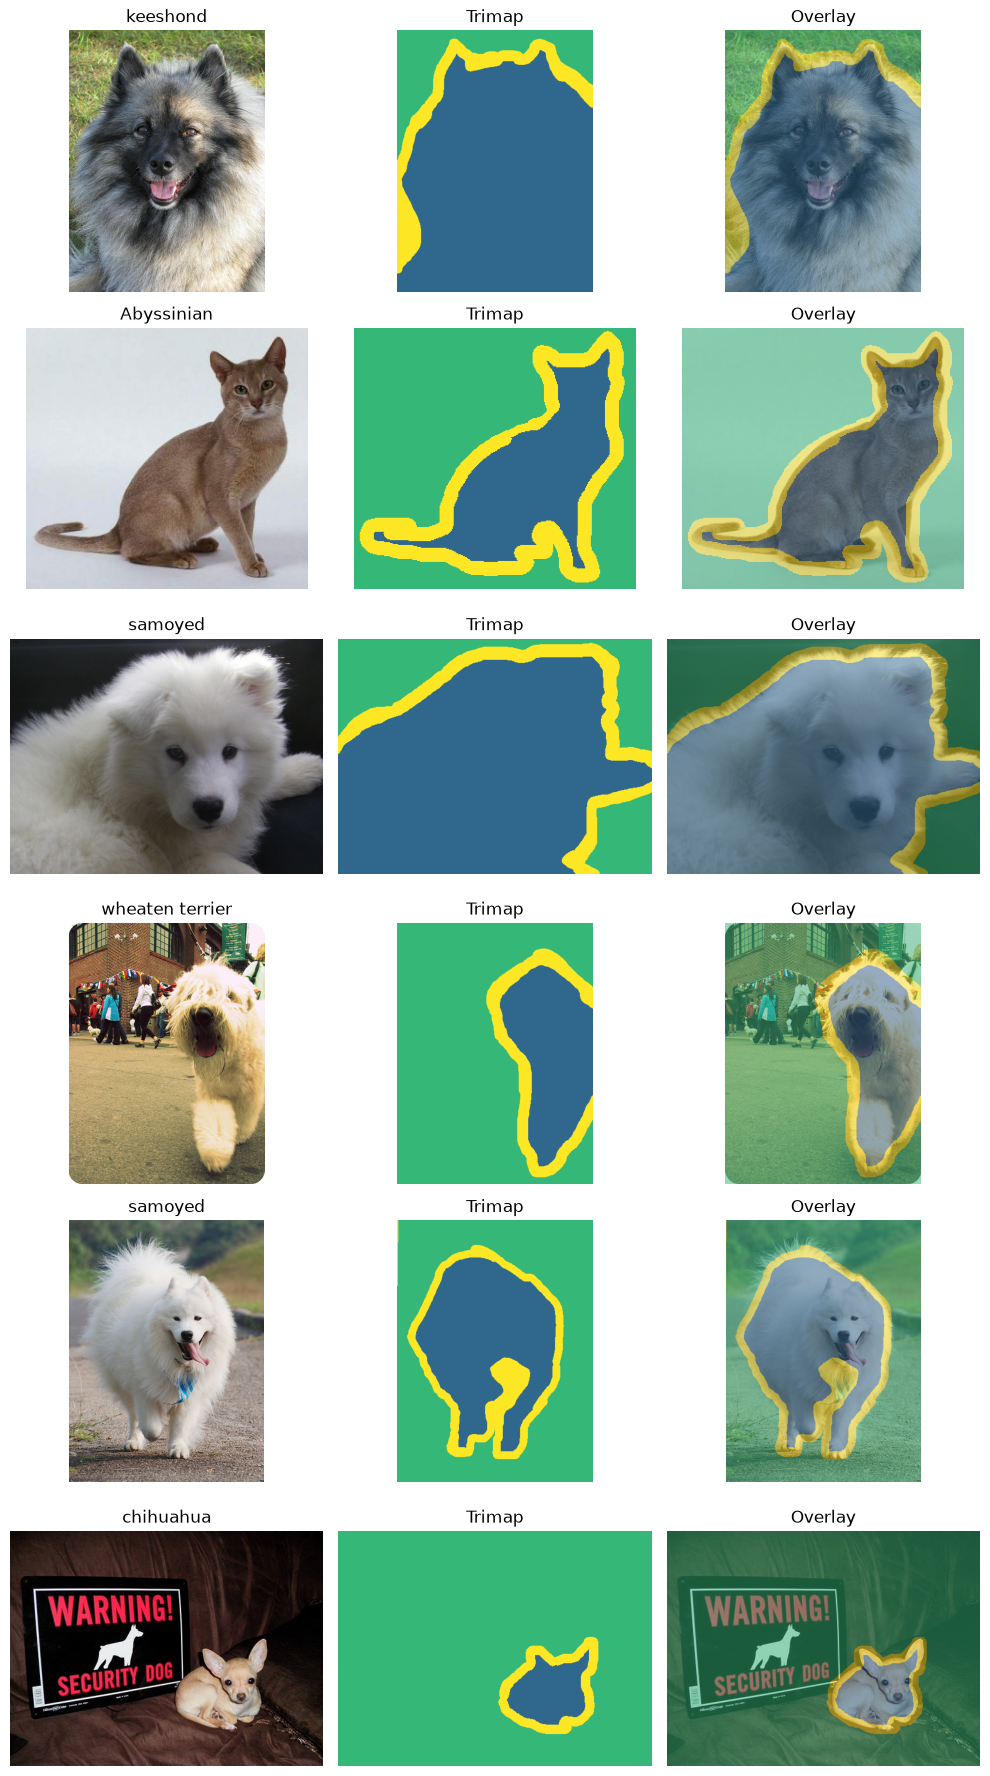

In [11]:
def breed_name(stem):
    return stem.rsplit("_", 1)[0].replace("_", " ")

picks = random.sample(mask_files, 6)
fig, axes = plt.subplots(6, 3, figsize=(10, 18))

for row, m in enumerate(picks):
    img = Image.open(IMAGES_DIR / (m.stem + ".jpg")).convert("RGB")
    mask = np.array(Image.open(m))

    axes[row, 0].imshow(img)
    axes[row, 0].set_title(breed_name(m.stem))
    axes[row, 1].imshow(mask, cmap="viridis", vmin=0, vmax=3)
    axes[row, 1].set_title("Trimap")
    axes[row, 2].imshow(img)
    axes[row, 2].imshow(mask, cmap="viridis", vmin=0, vmax=3, alpha=0.5)
    axes[row, 2].set_title("Overlay")
    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

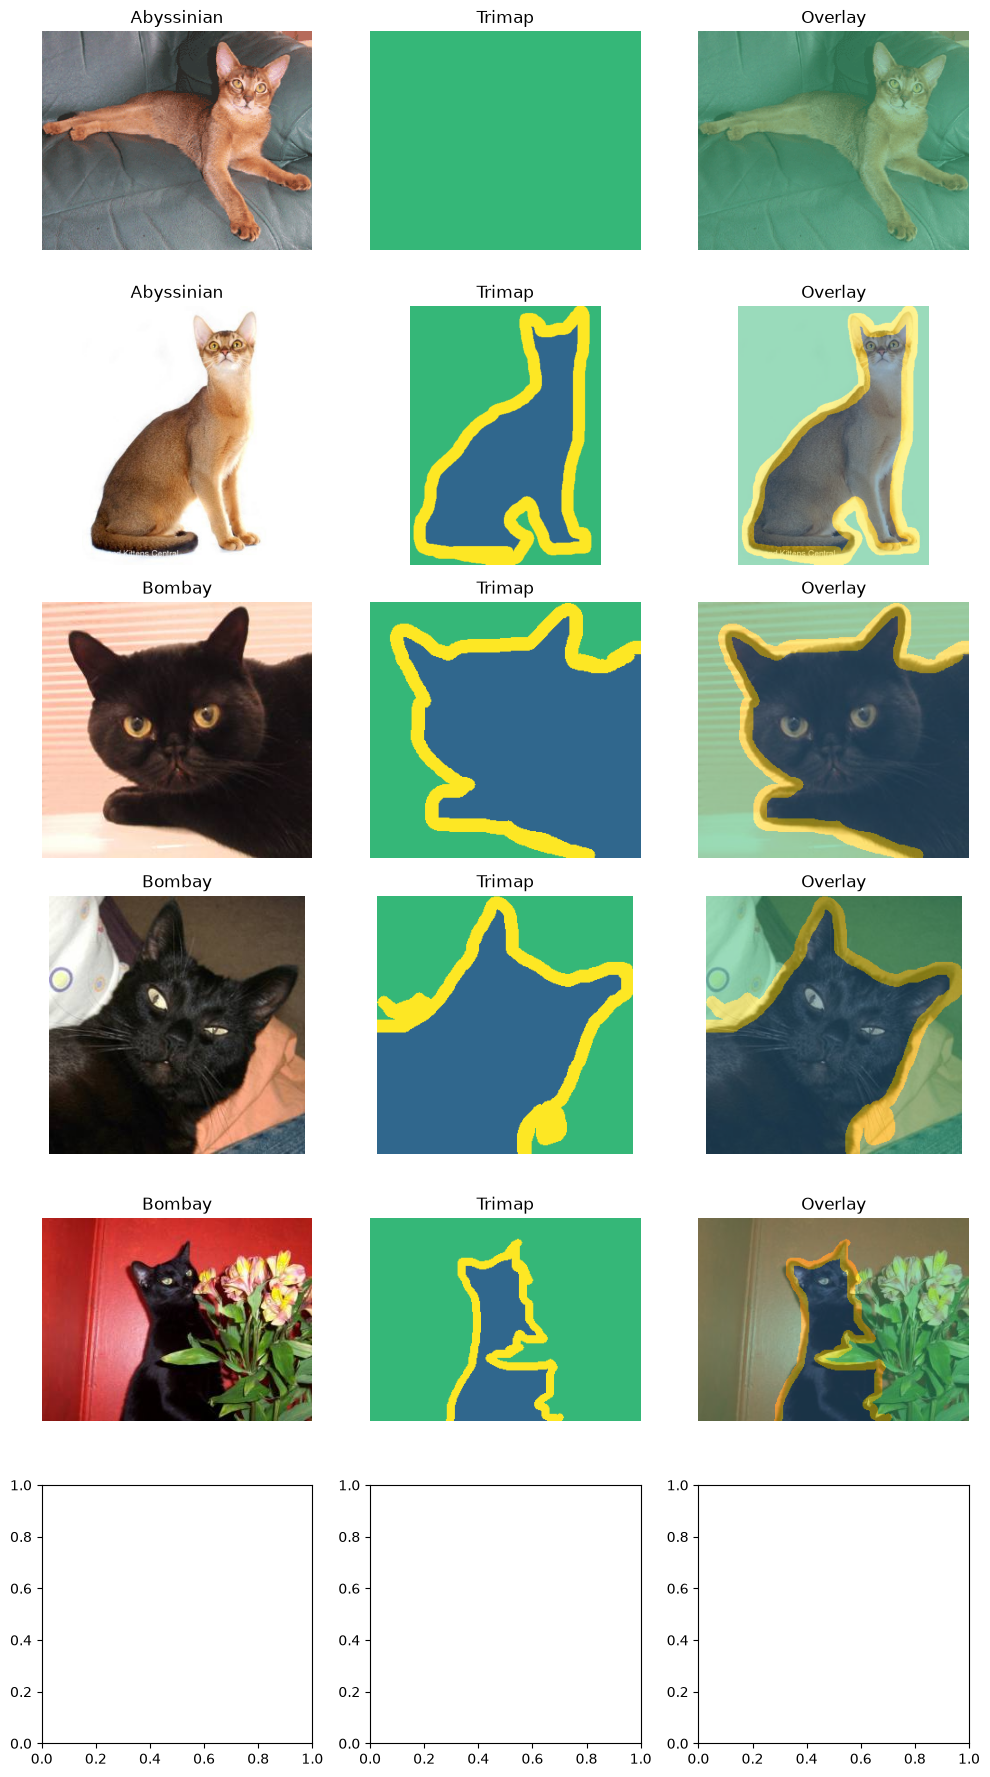

In [12]:
not_annotated_mask_files = sorted(f for f in MASKS_DIR.glob("*.png") if not f.name.startswith("._") and f.stem in not_annotated)

def breed_name(stem):
    return stem.rsplit("_", 1)[0].replace("_", " ")

sample_breed = [
    "Abyssinian_34", "Abyssinian_82", "Bombay_11",
    "Bombay_189", "Bombay_190"
]

picks = sample_breed
fig, axes = plt.subplots(6, 3, figsize=(10, 18))


for row, m in enumerate(picks):
    img = Image.open(IMAGES_DIR / (m + ".jpg")).convert("RGB")
    mask = np.array(Image.open(MASKS_DIR / (m + ".png")))

    axes[row, 0].imshow(img)
    axes[row, 0].set_title(breed_name(m))
    axes[row, 1].imshow(mask, cmap="viridis", vmin=0, vmax=3)
    axes[row, 1].set_title("Trimap")
    axes[row, 2].imshow(img)
    axes[row, 2].imshow(mask, cmap="viridis", vmin=0, vmax=3, alpha=0.5)
    axes[row, 2].set_title("Overlay")
    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [22]:
mask_list = sorted(f for f in MASKS_DIR.glob("*.png") if not f.name.startswith("._") and f.stem in annotated_stems)
len(mask_list)

7349

In [25]:
mask_list[0]

WindowsPath('../data/raw/oxford-iiit-pet/annotations/trimaps/Abyssinian_1.png')

In [26]:
pixel_fraction = {}

for m in mask_list:
    with Image.open(m) as mask:
        arr = np.array(mask)
        pixel_fraction[m.stem] = np.count_nonzero(arr == 1) / arr.size

In [31]:
import pandas as pd

pet_pixel_df = pd.DataFrame(
    pixel_fraction.items(),
    columns=["stem", "pet_fraction"]
)

pet_pixel_df

,stem,pet_fraction
0,Abyssinian_1,0.095575
1,Abyssinian_10,0.165707
2,Abyssinian_100,0.268051
3,Abyssinian_101,0.109279
4,Abyssinian_102,0.527591
...,...,...
7344,yorkshire_terrier_95,0.119964
7345,yorkshire_terrier_96,0.350878
7346,yorkshire_terrier_97,0.195642
7347,yorkshire_terrier_98,0.084528


In [32]:
pet_pixel_df.shape

(7349, 2)

In [33]:
def breed_name(stem):
    return stem.rsplit("_", 1)[0].replace("_", " ")

In [36]:
pet_pixel_df["breed"] = [breed_name(f.stem) for f in MASKS_DIR.glob("*.png") if not f.name.startswith("._") and f.stem in annotated_stems]

In [37]:
pet_pixel_df

,stem,pet_fraction,breed
0,Abyssinian_1,0.095575,Abyssinian
1,Abyssinian_10,0.165707,Abyssinian
2,Abyssinian_100,0.268051,Abyssinian
3,Abyssinian_101,0.109279,Abyssinian
4,Abyssinian_102,0.527591,Abyssinian
...,...,...,...
7344,yorkshire_terrier_95,0.119964,yorkshire terrier
7345,yorkshire_terrier_96,0.350878,yorkshire terrier
7346,yorkshire_terrier_97,0.195642,yorkshire terrier
7347,yorkshire_terrier_98,0.084528,yorkshire terrier


In [38]:
pet_pixel_df.describe()

,pet_fraction
count,7349.000000
mean,0.299767
std,0.164360
min,0.000000
25%,0.173022
50%,0.274097
75%,0.402847
max,0.946795


In [40]:
len(pet_pixel_df[pet_pixel_df["pet_fraction"] == 0])

14

In [41]:
len(pet_pixel_df[pet_pixel_df["pet_fraction"] < 0.01])

14

In [42]:
len(pet_pixel_df[pet_pixel_df["pet_fraction"] < 0.05])

147

In [44]:
pet_pixel_df.sort_values(by="pet_fraction", ascending=True)

,stem,pet_fraction,breed
3477,japanese_chin_199,0.000000,japanese chin
2274,Egyptian_Mau_196,0.000000,Egyptian Mau
4211,miniature_pinscher_14,0.000000,miniature pinscher
2279,Egyptian_Mau_20,0.000000,Egyptian Mau
7055,wheaten_terrier_195,0.000000,wheaten terrier
...,...,...,...
1834,British_Shorthair_16,0.903728,British Shorthair
7082,wheaten_terrier_39,0.904198,wheaten terrier
1345,Birman_51,0.940217,Birman
3748,keeshond_83,0.946629,keeshond


In [48]:
zero_pet_stem = pet_pixel_df.loc[
    pet_pixel_df["pet_fraction"] == 0,
    "stem"
]

In [51]:
zero_pet_stem = zero_pet_stem.to_list()

In [54]:
zero_mask_files = sorted(f for f in MASKS_DIR.iterdir() if not f.name.startswith("._") and f.stem in zero_pet_stem)

for m in zero_mask_files:
    with Image.open(m) as mask:
        arr = np.array(mask)
        print("Image", m, end=" ")
        print(np.unique(arr))

Image ..\data\raw\oxford-iiit-pet\annotations\trimaps\Egyptian_Mau_162.png [2]
Image ..\data\raw\oxford-iiit-pet\annotations\trimaps\Egyptian_Mau_165.png [2]
Image ..\data\raw\oxford-iiit-pet\annotations\trimaps\Egyptian_Mau_196.png [2]
Image ..\data\raw\oxford-iiit-pet\annotations\trimaps\Egyptian_Mau_20.png [2]
Image ..\data\raw\oxford-iiit-pet\annotations\trimaps\japanese_chin_199.png [2]
Image ..\data\raw\oxford-iiit-pet\annotations\trimaps\keeshond_7.png [2]
Image ..\data\raw\oxford-iiit-pet\annotations\trimaps\leonberger_18.png [2]
Image ..\data\raw\oxford-iiit-pet\annotations\trimaps\miniature_pinscher_14.png [2]
Image ..\data\raw\oxford-iiit-pet\annotations\trimaps\Persian_259.png [2]
Image ..\data\raw\oxford-iiit-pet\annotations\trimaps\saint_bernard_108.png [2]
Image ..\data\raw\oxford-iiit-pet\annotations\trimaps\saint_bernard_15.png [2]
Image ..\data\raw\oxford-iiit-pet\annotations\trimaps\saint_bernard_60.png [2]
Image ..\data\raw\oxford-iiit-pet\annotations\trimaps\saint_

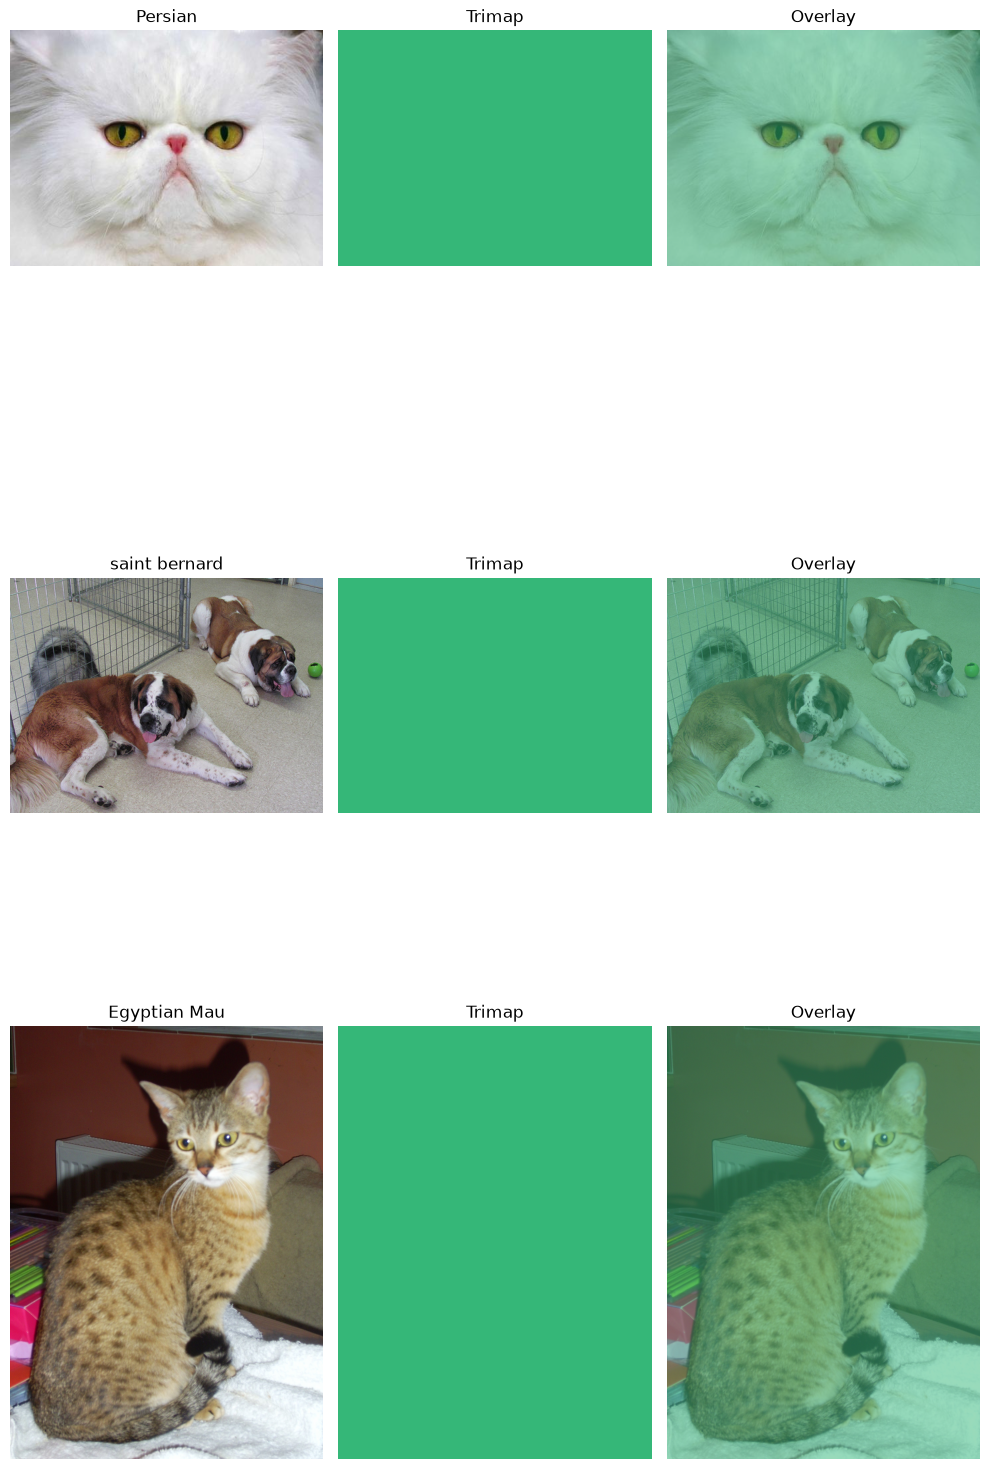

In [55]:
def breed_name(stem):
    return stem.rsplit("_", 1)[0].replace("_", " ")

picks = random.sample(zero_mask_files, 3)
fig, axes = plt.subplots(3, 3, figsize=(10, 18))

for row, m in enumerate(picks):
    img = Image.open(IMAGES_DIR / (m.stem + ".jpg")).convert("RGB")
    mask = np.array(Image.open(m))

    axes[row, 0].imshow(img)
    axes[row, 0].set_title(breed_name(m.stem))
    axes[row, 1].imshow(mask, cmap="viridis", vmin=0, vmax=3)
    axes[row, 1].set_title("Trimap")
    axes[row, 2].imshow(img)
    axes[row, 2].imshow(mask, cmap="viridis", vmin=0, vmax=3, alpha=0.5)
    axes[row, 2].set_title("Overlay")
    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [57]:
small_pet_stem = pet_pixel_df.loc[
    (pet_pixel_df["pet_fraction"] < 0.05)
    & (pet_pixel_df["pet_fraction"] > 0.01),
    "stem"
]

In [60]:
small_pet_stem = small_pet_stem.to_list()

AttributeError: 'list' object has no attribute 'to_list'

In [61]:
len(small_pet_stem)

133

In [59]:
small_mask_files = sorted(f for f in MASKS_DIR.iterdir() if not f.name.startswith("._") and f.stem in small_pet_stem)

for m in small_mask_files:
    with Image.open(m) as mask:
        arr = np.array(mask)
        print("Image", m, end=" ")
        print(np.unique(arr))

Image ..\data\raw\oxford-iiit-pet\annotations\trimaps\american_bulldog_100.png [1 2 3]
Image ..\data\raw\oxford-iiit-pet\annotations\trimaps\american_bulldog_121.png [1 2 3]
Image ..\data\raw\oxford-iiit-pet\annotations\trimaps\american_bulldog_123.png [1 2 3]
Image ..\data\raw\oxford-iiit-pet\annotations\trimaps\american_bulldog_62.png [1 2 3]
Image ..\data\raw\oxford-iiit-pet\annotations\trimaps\american_bulldog_80.png [1 2 3]
Image ..\data\raw\oxford-iiit-pet\annotations\trimaps\american_pit_bull_terrier_88.png [1 2 3]
Image ..\data\raw\oxford-iiit-pet\annotations\trimaps\basset_hound_137.png [1 2 3]
Image ..\data\raw\oxford-iiit-pet\annotations\trimaps\basset_hound_196.png [1 2 3]
Image ..\data\raw\oxford-iiit-pet\annotations\trimaps\basset_hound_197.png [1 2 3]
Image ..\data\raw\oxford-iiit-pet\annotations\trimaps\basset_hound_35.png [1 2 3]
Image ..\data\raw\oxford-iiit-pet\annotations\trimaps\basset_hound_58.png [1 2 3]
Image ..\data\raw\oxford-iiit-pet\annotations\trimaps\basse

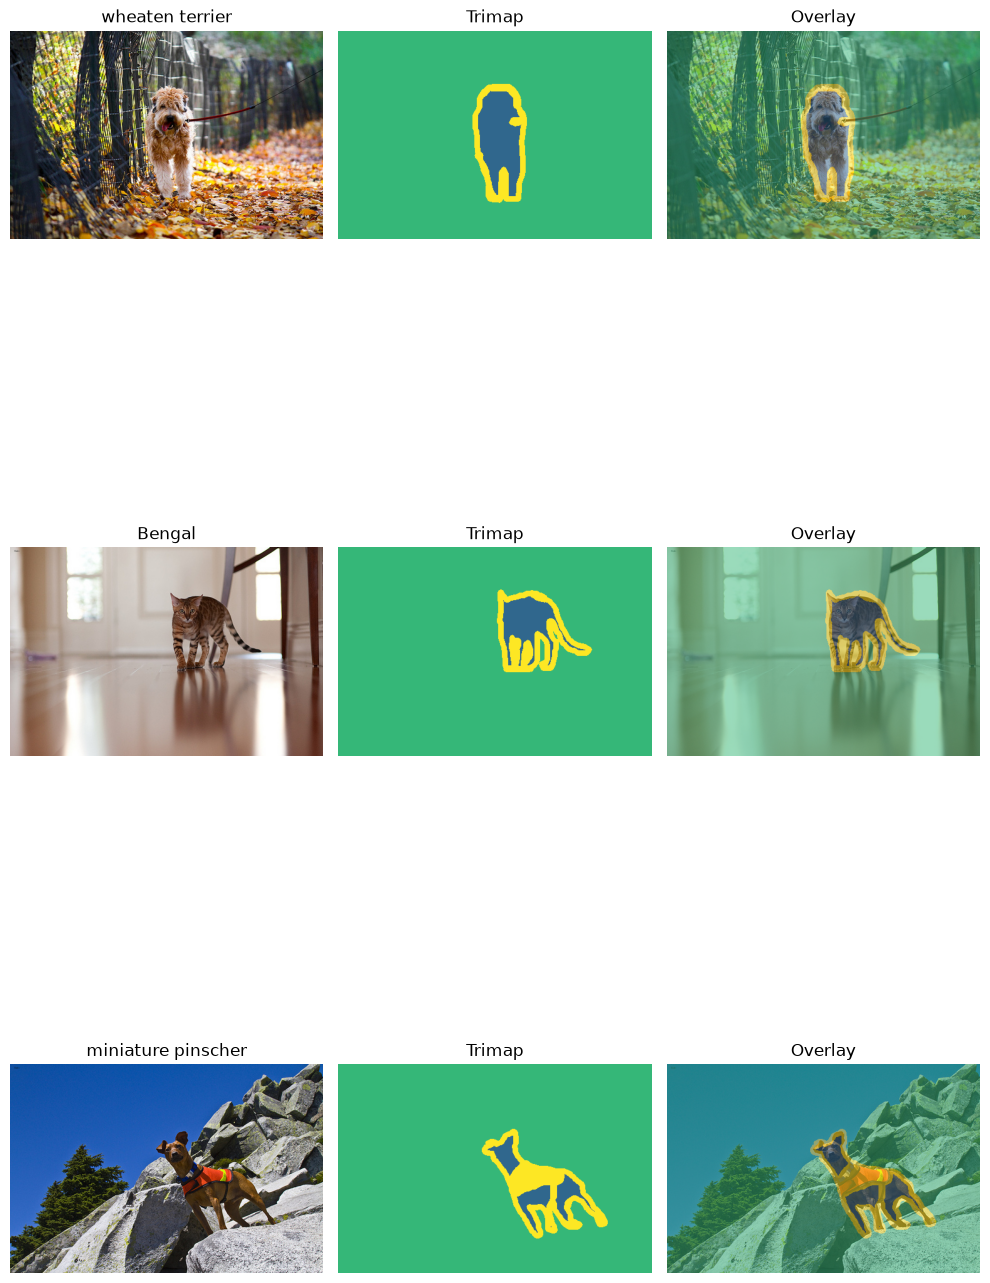

In [62]:
def breed_name(stem):
    return stem.rsplit("_", 1)[0].replace("_", " ")

picks = random.sample(small_mask_files, 3)
fig, axes = plt.subplots(3, 3, figsize=(10, 18))

for row, m in enumerate(picks):
    img = Image.open(IMAGES_DIR / (m.stem + ".jpg")).convert("RGB")
    mask = np.array(Image.open(m))

    axes[row, 0].imshow(img)
    axes[row, 0].set_title(breed_name(m.stem))
    axes[row, 1].imshow(mask, cmap="viridis", vmin=0, vmax=3)
    axes[row, 1].set_title("Trimap")
    axes[row, 2].imshow(img)
    axes[row, 2].imshow(mask, cmap="viridis", vmin=0, vmax=3, alpha=0.5)
    axes[row, 2].set_title("Overlay")
    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [63]:
pet_pixel_df

,stem,pet_fraction,breed
0,Abyssinian_1,0.095575,Abyssinian
1,Abyssinian_10,0.165707,Abyssinian
2,Abyssinian_100,0.268051,Abyssinian
3,Abyssinian_101,0.109279,Abyssinian
4,Abyssinian_102,0.527591,Abyssinian
...,...,...,...
7344,yorkshire_terrier_95,0.119964,yorkshire terrier
7345,yorkshire_terrier_96,0.350878,yorkshire terrier
7346,yorkshire_terrier_97,0.195642,yorkshire terrier
7347,yorkshire_terrier_98,0.084528,yorkshire terrier


In [69]:
clean_df = pet_pixel_df.loc[pet_pixel_df["pet_fraction"] != 0]
len(pet_pixel_df)

7335

In [70]:
from sklearn.model_selection import train_test_split

SEED = 42

train_df, holdout_df = train_test_split(
    clean_df,
    test_size=0.30,
    stratify=clean_df["breed"],
    random_state=SEED,
)

In [71]:
val_df, test_df = train_test_split(
    holdout_df,
    test_size=0.50,
    stratify=holdout_df["breed"],
    random_state=SEED,
)

In [72]:
train_df = train_df.assign(split="train")
val_df = val_df.assign(split="val")
test_df = test_df.assign(split="test")
split_df = pd.concat([train_df, val_df, test_df]).reset_index(drop=True)

In [73]:
print("Sizes:", len(train_df), len(val_df), len(test_df))

train_s, val_s, test_s = set(train_df["stem"]), set(val_df["stem"]), set(test_df["stem"])
print("Overlap train/val:", len(train_s & val_s))
print("Overlap train/test:", len(train_s & test_s))
print("Overlap val/test:", len(val_s & test_s))

for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name}: breeds={part['breed'].nunique()}, "
          f"min per breed={part['breed'].value_counts().min()}, "
          f"mean pet_fraction={part['pet_fraction'].mean():.3f}")

Sizes: 5134 1100 1101
Overlap train/val: 0
Overlap train/test: 0
Overlap val/test: 0
train: breeds=37, min per breed=129, mean pet_fraction=0.299
val: breeds=37, min per breed=28, mean pet_fraction=0.303
test: breeds=37, min per breed=27, mean pet_fraction=0.302


In [74]:
split_df[["stem", "breed", "pet_fraction", "split"]].to_csv(
    "../data/processed/split.csv", index=False
)